# 06 · Arena and Decisions

The scoreboard and the guide. Every method across a ladder of sizes, scored on **gap to optimal**
(against the exact optimum where it exists, a strong best-known elsewhere) and **solve time**. The
crossover is the whole story: exact wins at tiny sizes, local search and OR-Tools dominate
everywhere else, and nearest-neighbor alone is a baseline, never a solution.

Ends with the decision framework — saved as JSON so it travels with the code.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from src.evaluation.gap_to_optimal import gap_percent
from src.evaluation.scaling import time_call
from src.exact.milp_tsp import milp_tsp
from src.heuristics.christofides_like import cheapest_insertion_tour, savings_tour
from src.heuristics.nearest_neighbor import nearest_neighbor_tour
from src.heuristics.two_opt import two_opt
from src.ortools_solver.routing import solve_tsp
from src.problems.tsp import generate_tsp_instance, tour_length
from src.reporting import save_figure, save_json

METHODS = {
    "nearest_neighbor": lambda d: nearest_neighbor_tour(d),
    "savings": lambda d: savings_tour(d),
    "cheapest_insertion": lambda d: cheapest_insertion_tour(d),
    "nn_2opt": lambda d: two_opt(nearest_neighbor_tour(d), d),
    "ortools_1s": lambda d: solve_tsp(d, time_limit=1.0)[0],
}


def reference(instance, n):
    if n <= 12:
        _, length = milp_tsp(instance.distances, time_limit=15.0)
        return length, "exact_milp"
    _, length = solve_tsp(instance.distances, time_limit=5.0)
    return length, "ortools_5s_best_known"

## 1. The scoreboard

For each size we average over three seeds: every method's gap to the reference and its runtime.

In [2]:
ladder = [10, 20, 30, 50]
seeds = [0, 1, 2]
gap = {m: {n: [] for n in ladder} for m in METHODS}
secs = {m: {n: [] for n in ladder} for m in METHODS}
ref_kind = {}
for n in ladder:
    for seed in seeds:
        inst = generate_tsp_instance(n, seed=seed)
        ref_len, ref_kind[n] = reference(inst, n)
        for m, fn in METHODS.items():
            tour, elapsed = time_call(lambda fn=fn, d=inst.distances: fn(d))
            gap[m][n].append(gap_percent(tour_length(tour, inst.distances), ref_len))
            secs[m][n].append(elapsed)

mean_gap = {m: {n: float(np.mean(v)) for n, v in d.items()} for m, d in gap.items()}
mean_secs = {m: {n: float(np.mean(v)) for n, v in d.items()} for m, d in secs.items()}

header = f"{'method':>20} " + " ".join(f"{('n=' + str(n)):>9}" for n in ladder)
print("gap to reference (%)\n" + header)
for m in METHODS:
    print(f"{m:>20} " + " ".join(f"{mean_gap[m][n]:>9.1f}" for n in ladder))

save_json("06_scoreboard", {
    "sizes": ladder, "seeds": seeds, "reference_by_size": ref_kind,
    "mean_gap_percent": mean_gap, "mean_seconds": mean_secs,
})

gap to reference (%)
              method      n=10      n=20      n=30      n=50
    nearest_neighbor       5.8      21.0      25.8      19.8
             savings       0.0       2.7       5.6       5.9
  cheapest_insertion      10.9       9.4      13.3      15.8
             nn_2opt       0.3       3.4       5.0       3.2
          ortools_1s       0.0       0.0       0.0       0.5


PosixPath('/workspaces/routing_arena/outputs/data/06_scoreboard.json')

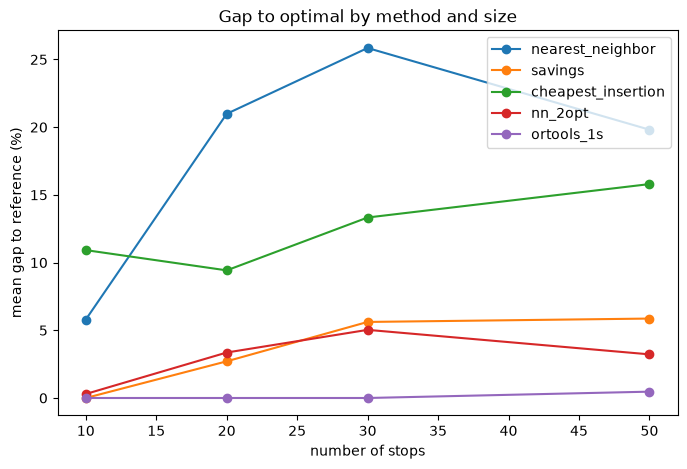

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for m in METHODS:
    ax.plot(ladder, [mean_gap[m][n] for n in ladder], "-o", label=m)
ax.set_xlabel("number of stops")
ax.set_ylabel("mean gap to reference (%)")
ax.set_title("Gap to optimal by method and size")
ax.legend()
save_figure(fig, "06_gap_vs_size")
plt.show()

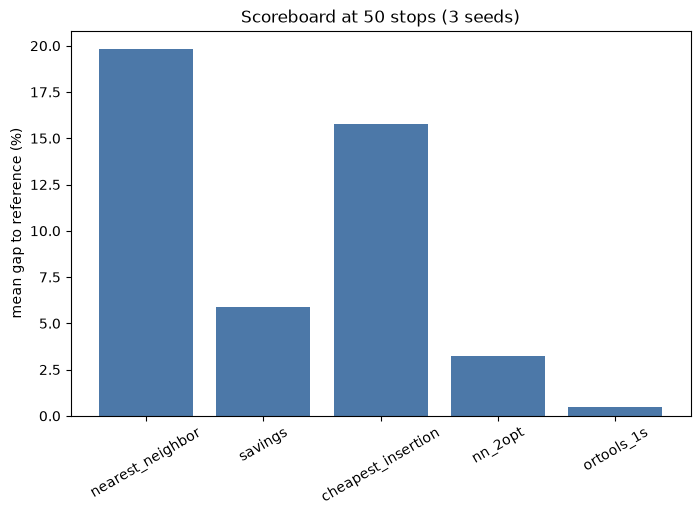

In [4]:
biggest = ladder[-1]
fig, ax = plt.subplots(figsize=(8, 5))
names = list(METHODS)
ax.bar(names, [mean_gap[m][biggest] for m in names], color="#4C78A8")
ax.set_ylabel("mean gap to reference (%)")
ax.set_title(f"Scoreboard at {biggest} stops ({len(seeds)} seeds)")
ax.tick_params(axis="x", rotation=30)
save_figure(fig, "06_scoreboard_gap")
plt.show()

## 2. The crossover

Where each method stops making sense. The exact MILP's solve time climbs off the top of the chart
in the high teens of stops; construction-plus-2-opt and a one-second OR-Tools run stay flat and
cheap across the whole range. That gap never closes — it is the factorial curve from notebook 01.

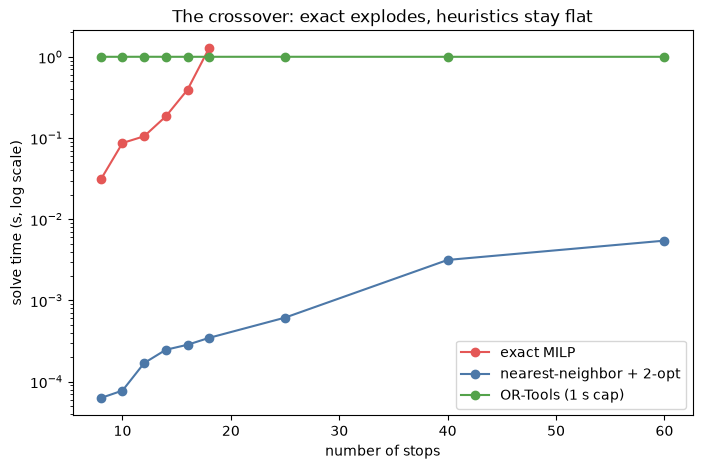

In [5]:
exact_sizes = [8, 10, 12, 14, 16, 18]
heur_sizes = [8, 10, 12, 14, 16, 18, 25, 40, 60]
crossover = {"exact_milp": {}, "nn_2opt": {}, "ortools_1s": {}}
for n in exact_sizes:
    inst = generate_tsp_instance(n, seed=42)
    _, t = time_call(lambda d=inst.distances: milp_tsp(d, time_limit=12.0))
    crossover["exact_milp"][n] = t
for n in heur_sizes:
    inst = generate_tsp_instance(n, seed=42)
    _, t2 = time_call(lambda d=inst.distances: two_opt(nearest_neighbor_tour(d), d))
    _, to = time_call(lambda d=inst.distances: solve_tsp(d, time_limit=1.0))
    crossover["nn_2opt"][n] = t2
    crossover["ortools_1s"][n] = to

save_json("06_crossover", crossover)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(exact_sizes, [crossover["exact_milp"][n] for n in exact_sizes],
            "-o", color="#E45756", label="exact MILP")
ax.semilogy(heur_sizes, [crossover["nn_2opt"][n] for n in heur_sizes],
            "-o", color="#4C78A8", label="nearest-neighbor + 2-opt")
ax.semilogy(heur_sizes, [crossover["ortools_1s"][n] for n in heur_sizes],
            "-o", color="#54A24B", label="OR-Tools (1 s cap)")
ax.set_xlabel("number of stops")
ax.set_ylabel("solve time (s, log scale)")
ax.set_title("The crossover: exact explodes, heuristics stay flat")
ax.legend()
save_figure(fig, "06_crossover")
plt.show()

## 3. The decision framework

The rule for picking a method, saved as JSON alongside the figures.

In [6]:
decision = {
    "rules": [
        {"when": "<= ~15-20 stops and you need a provable optimum",
         "use": "exact MILP with subtour elimination (CBC)"},
        {"when": "larger plain-TSP instances",
         "use": "a construction plus 2-opt (nearest-neighbor + 2-opt, optionally or-opt)"},
        {"when": "capacities, multiple vehicles, or time windows",
         "use": "OR-Tools guided local search"},
        {"when": "production, any size",
         "use": "never nearest-neighbor alone -- it is a baseline, not a solution"},
    ],
    "always": "know your gap-to-optimal by checking against exact on a small same-type instance",
    "thesis": "give up on optimality on purpose; a 2%-from-optimal route in one second beats a "
              "proven-optimal route delivered never",
}
for rule in decision["rules"]:
    print(f"- {rule['when']}\n    -> {rule['use']}")
print(f"\nAlways: {decision['always']}")

save_json("06_decision_framework", decision)

- <= ~15-20 stops and you need a provable optimum
    -> exact MILP with subtour elimination (CBC)
- larger plain-TSP instances
    -> a construction plus 2-opt (nearest-neighbor + 2-opt, optionally or-opt)
- capacities, multiple vehicles, or time windows
    -> OR-Tools guided local search
- production, any size
    -> never nearest-neighbor alone -- it is a baseline, not a solution

Always: know your gap-to-optimal by checking against exact on a small same-type instance


PosixPath('/workspaces/routing_arena/outputs/data/06_decision_framework.json')

## The close

Give up on optimality on purpose. Pick the method by size and constraints: exact when it is small
and proof matters, a construction plus 2-opt otherwise, OR-Tools once there are capacities or time
windows — and never nearest-neighbor alone. Always know your gap-to-optimal by checking against
exact on a small instance of the same type.

The exact optimum you cannot compute and the near-optimum you can compute in a second are, for
every practical purpose, the same route. The whole discipline of real-world routing is knowing
that.